In [1]:
from src.dataset_overview import load_data,data_understanding
import pandas as pd
from src.data_preprocessing import (
    analyze_outliers,analyze_duplicates,
    analyze_missing_values,analyze_inconsistency,
    convert_data_types,handle_duplicates,handle_missing_values,handle_outliers,save_cleaned_data
)
from src.exploratory_data_analysis import separate_feature_types


In [2]:
path = "../data/raw/Cardiovascular_Disease_Dataset.csv"
target = "target"

# path = "../data/raw/dataset_regresi_dummy_110.csv"
# target = "harga_rumah_juta" 

df_sample = load_data(file_path=path)
df_sample.head()

# data_kotor = {
#         "ID_Pelanggan": [101, 102, 103, 103, 104, 105, 106, 10009],
#         "Kota": ["Jakarta", "jakarta ", "BANDUNG", "BANDUNG", "Surabaya", "surabaya", None, "Medan"],
#         "Usia": [25, 30, 28, 28, -5, 42, 150, 35],          # Ada nilai negatif (-5) dan outlier (150)
#         "Pendapatan": [5000, 6200, 5800, 5800, None, 7100, 95000, 6000], # Ada missing value & outlier (95000)
#         "Status_Aktif": ["Ya", "ya", "Tidak", "Tidak", "YA ", None, "Tidak", "N/A"]
#     }

# df_sample = pd.DataFrame(data_kotor)
threshold = 3

In [3]:
res_missing = analyze_missing_values(df_sample, plot=True)

Tidak ditemukan missing value pada dataset.



Total Baris Dataset        : 1000
Duplikat Persis (Full Row) : 0 baris (0.00%)
Tidak ditemukan baris duplikat persis.



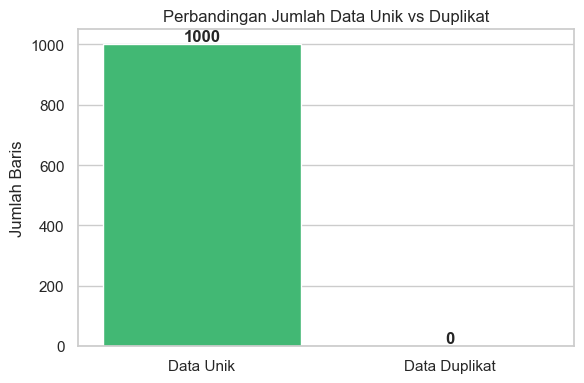

In [4]:
res_duplicates = analyze_duplicates(df_sample, plot=True)

,Batas_Bawah,Batas_Atas,Jumlah_Outlier,Persentase (%),Min_Aktual,Max_Aktual
Kolom,,,,,,
patientid,-5181716.75,15400033.25,0,0.0,103368.0,9990855.0
age,-11.38,109.62,0,0.0,20.0,80.0
chestpain,-3.00,5.00,0,0.0,0.0,3.0
restingBP,51.00,259.00,0,0.0,94.0,200.0
serumcholestrol,-17.00,657.00,0,0.0,0.0,602.0
maxheartrate,36.88,257.88,0,0.0,71.0,202.0
oldpeak,-2.90,8.30,0,0.0,0.0,6.2
slope,-0.50,3.50,0,0.0,0.0,3.0
noofmajorvessels,-3.00,5.00,0,0.0,0.0,3.0


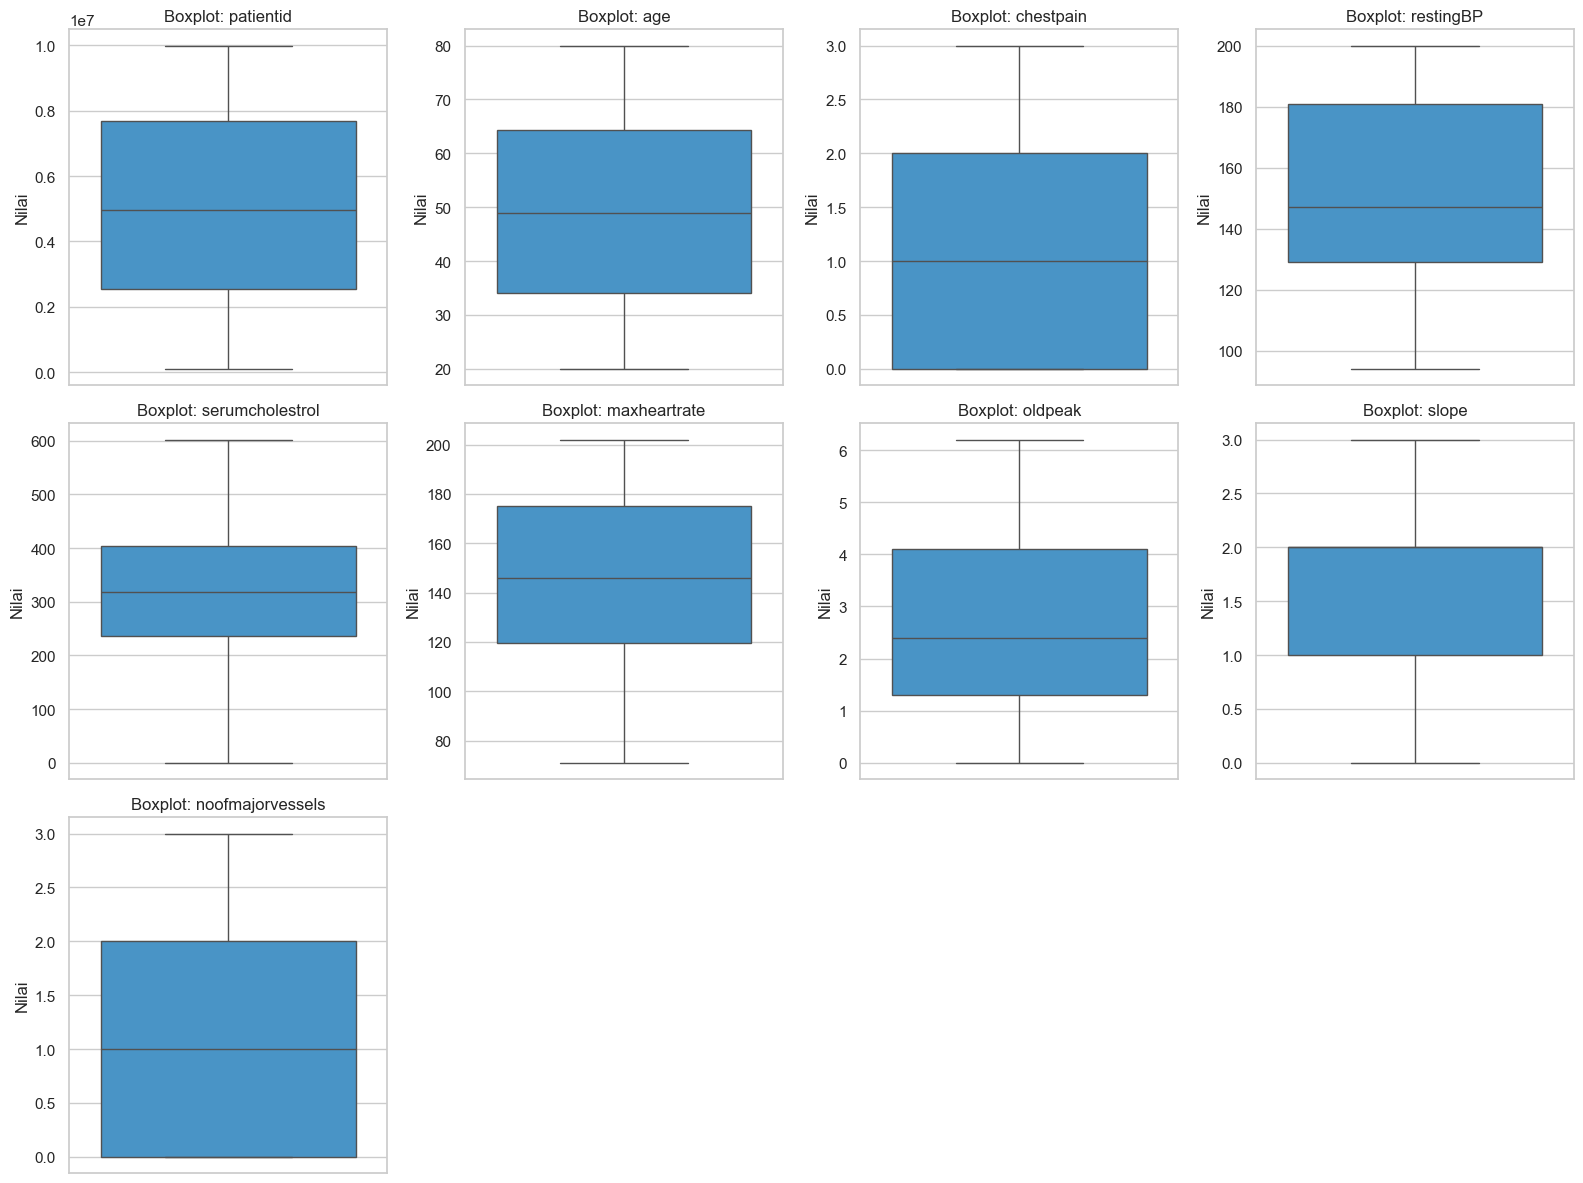

In [5]:
res_outliers = analyze_outliers(df_sample, plot=True,cat_threshold=threshold)

In [6]:
res_inconsistency = analyze_inconsistency(df_sample,cat_threshold=threshold)

tidak ditemukan masalah, namun perlu di cek ulang lagi



In [7]:
# raw_df = pd.DataFrame({
#     'user_id': [101, 102, 102, 103, 104, 105, 106],
#     'tgl_transaksi': ['2026-05-01', '2026-05-02', '2026-05-02', 'salah_format', '2026-05-04', '2026-05-05', '2026-05-06'],
#     'umur': ['25', '30', '30', '28', '-5', '35', '150'],                 # -5 dan 150 tidak masuk akal secara konteks
#     'nominal': ['Rp 150.000', 'Rp 200.000', 'Rp 200.000', None, 'Rp 180.000', 'Rp 190.000', 'Rp 9.500.000']
# })

raw_df = df_sample
data_understanding(df=raw_df,cat_threshold=threshold)


=== 1. SHAPE & DATA TYPES ===
Jumlah Baris  : 1000
Jumlah Kolom  : 14
Baris Duplikat: 0



,Dtype,Non-Null,Missing,Missing-Percentage,Unique
patientid,int64,1000,0,0.0,1000
age,int64,1000,0,0.0,61
gender,int64,1000,0,0.0,2
chestpain,int64,1000,0,0.0,4
restingBP,int64,1000,0,0.0,95
serumcholestrol,int64,1000,0,0.0,344
fastingbloodsugar,int64,1000,0,0.0,2
restingrelectro,int64,1000,0,0.0,3
maxheartrate,int64,1000,0,0.0,129
exerciseangia,int64,1000,0,0.0,2



=== 2. DATASET OVERVIEW (5 BARIS PERTAMA) ===


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1



=== 3. STATISTICAL SUMMARY ===
[Info] Fitur numerik terdeteksi sebagai encoded-categorical: ['gender', 'fastingbloodsugar', 'restingrelectro', 'exerciseangia', 'target']
Fitur Numerik:


,count,mean,std,min,25%,50%,75%,max
patientid,1000.0,5.048704e+06,2.895905e+06,103368.0,2536439.50,4952508.5,7681877.00,9990855.0
age,1000.0,4.924200e+01,1.786473e+01,20.0,34.00,49.0,64.25,80.0
chestpain,1000.0,9.800000e-01,9.531571e-01,0.0,0.00,1.0,2.00,3.0
restingBP,1000.0,1.517470e+02,2.996523e+01,94.0,129.00,147.0,181.00,200.0
serumcholestrol,1000.0,3.114470e+02,1.324438e+02,0.0,235.75,318.0,404.25,602.0
maxheartrate,1000.0,1.454770e+02,3.419027e+01,71.0,119.75,146.0,175.00,202.0
oldpeak,1000.0,2.707700e+00,1.720753e+00,0.0,1.30,2.4,4.10,6.2
slope,1000.0,1.540000e+00,1.003697e+00,0.0,1.00,2.0,2.00,3.0
noofmajorvessels,1000.0,1.222000e+00,9.775846e-01,0.0,0.00,1.0,2.00,3.0


Fitur Kategorikal / Non-Numerik:


,count,unique,top,freq
gender,1000,2,1,765
fastingbloodsugar,1000,2,0,704
restingrelectro,1000,3,0,454
exerciseangia,1000,2,0,502
target,1000,2,1,580


In [8]:
df_clean = convert_data_types(df=raw_df,dtype_map={'umur':'int64','nominal':'float64'},date_cols=['tgl_transaksi'])


[Type Conversion] Kolom dikonversi: Tidak ada


In [9]:
data_understanding(df=df_clean,cat_threshold=threshold)

=== 1. SHAPE & DATA TYPES ===
Jumlah Baris  : 1000
Jumlah Kolom  : 14
Baris Duplikat: 0



,Dtype,Non-Null,Missing,Missing-Percentage,Unique
patientid,int64,1000,0,0.0,1000
age,int64,1000,0,0.0,61
gender,int64,1000,0,0.0,2
chestpain,int64,1000,0,0.0,4
restingBP,int64,1000,0,0.0,95
serumcholestrol,int64,1000,0,0.0,344
fastingbloodsugar,int64,1000,0,0.0,2
restingrelectro,int64,1000,0,0.0,3
maxheartrate,int64,1000,0,0.0,129
exerciseangia,int64,1000,0,0.0,2



=== 2. DATASET OVERVIEW (5 BARIS PERTAMA) ===


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1



=== 3. STATISTICAL SUMMARY ===
[Info] Fitur numerik terdeteksi sebagai encoded-categorical: ['gender', 'fastingbloodsugar', 'restingrelectro', 'exerciseangia', 'target']
Fitur Numerik:


,count,mean,std,min,25%,50%,75%,max
patientid,1000.0,5.048704e+06,2.895905e+06,103368.0,2536439.50,4952508.5,7681877.00,9990855.0
age,1000.0,4.924200e+01,1.786473e+01,20.0,34.00,49.0,64.25,80.0
chestpain,1000.0,9.800000e-01,9.531571e-01,0.0,0.00,1.0,2.00,3.0
restingBP,1000.0,1.517470e+02,2.996523e+01,94.0,129.00,147.0,181.00,200.0
serumcholestrol,1000.0,3.114470e+02,1.324438e+02,0.0,235.75,318.0,404.25,602.0
maxheartrate,1000.0,1.454770e+02,3.419027e+01,71.0,119.75,146.0,175.00,202.0
oldpeak,1000.0,2.707700e+00,1.720753e+00,0.0,1.30,2.4,4.10,6.2
slope,1000.0,1.540000e+00,1.003697e+00,0.0,1.00,2.0,2.00,3.0
noofmajorvessels,1000.0,1.222000e+00,9.775846e-01,0.0,0.00,1.0,2.00,3.0


Fitur Kategorikal / Non-Numerik:


,count,unique,top,freq
gender,1000,2,1,765
fastingbloodsugar,1000,2,0,704
restingrelectro,1000,3,0,454
exerciseangia,1000,2,0,502
target,1000,2,1,580


In [10]:
clean_missing = handle_missing_values(df=df_clean,strategy={'tgl_transaksi': 'drop', 'nominal': 'median'},cat_threshold=threshold)
clean_missing

[Info] Fitur numerik terdeteksi sebagai encoded-categorical: ['gender', 'fastingbloodsugar', 'restingrelectro', 'exerciseangia', 'target']
[Missing Values] Tidak ada missing value.


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,9949544,48,1,2,139,349,0,2,183,1,5.6,2,2,1
996,9953423,47,1,3,143,258,1,1,98,1,5.7,1,0,0
997,9965859,69,1,0,156,434,1,0,196,0,1.4,3,1,1
998,9988507,45,1,1,186,417,0,1,117,1,5.9,3,2,1


In [11]:
clean_duplicatet = handle_duplicates(clean_missing)
clean_duplicatet

[Duplicate Handling] Dihapus 0 baris duplikat (Sisa: 1000 baris)


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,9949544,48,1,2,139,349,0,2,183,1,5.6,2,2,1
996,9953423,47,1,3,143,258,1,1,98,1,5.7,1,0,0
997,9965859,69,1,0,156,434,1,0,196,0,1.4,3,1,1
998,9988507,45,1,1,186,417,0,1,117,1,5.9,3,2,1


In [12]:
clean_outlier1 = handle_outliers(df=clean_duplicatet,cols=['umur'], action='drop', custom_bounds={'umur': (17, 90)})
clean_outlier1

[Outlier Handling] Tidak ada outlier terdeteksi


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,9949544,48,1,2,139,349,0,2,183,1,5.6,2,2,1
996,9953423,47,1,3,143,258,1,1,98,1,5.7,1,0,0
997,9965859,69,1,0,156,434,1,0,196,0,1.4,3,1,1
998,9988507,45,1,1,186,417,0,1,117,1,5.9,3,2,1


In [13]:
clean_outlier2 = handle_outliers(df=clean_outlier1,cols=['nominal'], method='iqr', action='cap', factor=1.5)
clean_outlier2

[Outlier Handling] Tidak ada outlier terdeteksi


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,9949544,48,1,2,139,349,0,2,183,1,5.6,2,2,1
996,9953423,47,1,3,143,258,1,1,98,1,5.7,1,0,0
997,9965859,69,1,0,156,434,1,0,196,0,1.4,3,1,1
998,9988507,45,1,1,186,417,0,1,117,1,5.9,3,2,1


In [14]:
clean_df = (
    raw_df
    .pipe(convert_data_types, dtype_map={'umur': 'int64', 'nominal': 'float64'}, date_cols=['tgl_transaksi'])
    .pipe(handle_duplicates, subset=['patientid'])
    .pipe(handle_missing_values, strategy={'tgl_transaksi': 'drop', 'nominal': 'median'},cat_threshold=threshold)
    .pipe(handle_outliers, cols=['umur'], action='drop', custom_bounds={'umur': (17, 90)})
    .pipe(handle_outliers, cols=['nominal'], method='iqr', action='cap', factor=1.5)
)

print("\n=== HASIL AKHIR ===")
clean_df

[Type Conversion] Kolom dikonversi: Tidak ada
[Duplicate Handling] Dihapus 0 baris duplikat (Sisa: 1000 baris)
[Info] Fitur numerik terdeteksi sebagai encoded-categorical: ['gender', 'fastingbloodsugar', 'restingrelectro', 'exerciseangia', 'target']
[Missing Values] Tidak ada missing value.
[Outlier Handling] Tidak ada outlier terdeteksi
[Outlier Handling] Tidak ada outlier terdeteksi

=== HASIL AKHIR ===


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,9949544,48,1,2,139,349,0,2,183,1,5.6,2,2,1
996,9953423,47,1,3,143,258,1,1,98,1,5.7,1,0,0
997,9965859,69,1,0,156,434,1,0,196,0,1.4,3,1,1
998,9988507,45,1,1,186,417,0,1,117,1,5.9,3,2,1


In [15]:
save_cleaned_data(df_clean, filename="Cardiovascular_Disease_Dataset",file_format='json')

[Save Data] file yang sama sudah dibuat


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,9949544,48,1,2,139,349,0,2,183,1,5.6,2,2,1
996,9953423,47,1,3,143,258,1,1,98,1,5.7,1,0,0
997,9965859,69,1,0,156,434,1,0,196,0,1.4,3,1,1
998,9988507,45,1,1,186,417,0,1,117,1,5.9,3,2,1
